[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/genesis/sdb/labs/worked_example.ipynb)

# Worked example: forecasting ChatGPT's attention, end to end

*School of Digital Business 5.0 — Time Series in the AI Era.*

One product, the whole procedure: **look at the data → backtest nine forecasters → read the errors, the
horizons and the intervals → combine → forecast → conclude.** The series is the daily number of views of
the English Wikipedia article on ChatGPT — a public proxy for attention to an AI product.

The notebook is stored **with its results**: you can read it without running anything. To rerun it in
Colab, use `Runtime → Run all`; the first run downloads three models (about 1.5 GB) and takes several
minutes.

## 0. Setup

In [1]:
!pip install -q chronos-forecasting statsforecast timesfm tirex-ts

In [2]:
import os, time, warnings
os.environ["NIXTLA_ID_AS_COL"] = "true"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
import transformers
transformers.utils.logging.disable_progress_bar()
transformers.utils.logging.set_verbosity_error()
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL, Naive, SeasonalNaive

plt.rcParams.update({"figure.figsize": (12, 3.6), "axes.grid": True, "grid.alpha": 0.3})
PINK, NAVY, TEAL, ORANGE, SLATE = "#e64173", "#181485", "#20B2AA", "#FFA500", "#314f4f"
CLASSICAL = {"Naive": lambda s: Naive(alias="Naive"),
             "Seasonal naive": lambda s: SeasonalNaive(s, alias="Seasonal naive"),
             "ETS": lambda s: AutoETS(season_length=s, alias="ETS"),
             "ARIMA": lambda s: AutoARIMA(season_length=s, alias="ARIMA"),
             "Theta": lambda s: AutoTheta(season_length=s, alias="Theta"),
             "MSTL": lambda s: MSTL(season_length=[s, 365], alias="MSTL")}
_loaded = {}


def foundation(name):
    # Load each foundation model once; the first call downloads its weights.
    if name not in _loaded:
        if name == "Chronos-2":
            from chronos import BaseChronosPipeline
            _loaded[name] = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
        elif name == "TimesFM":
            import timesfm
            m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
            m.compile(timesfm.ForecastConfig(max_context=1024, max_horizon=128, normalize_inputs=True,
                                             use_continuous_quantile_head=True))
            _loaded[name] = m
        elif name == "TiRex":
            import tirex
            _loaded[name] = tirex.load_model("NX-AI/TiRex", device="cpu")
    return _loaded[name]


def forecast_fm(name, history, h):
    # Median and 80% interval (P10, P90) from a foundation model, for one series.
    ctx = torch.tensor(np.asarray(history, dtype=np.float32))
    model = foundation(name)
    if name == "Chronos-2":
        q, _ = model.predict_quantiles([ctx], prediction_length=h, quantile_levels=[0.1, 0.5, 0.9])
        q = np.asarray(q[0]).reshape(h, 3)
        return q[:, 1], q[:, 0], q[:, 2]
    if name == "TimesFM":
        point, q = model.forecast(horizon=h, inputs=[ctx.numpy()])
        q = np.asarray(q)[0]
        return np.asarray(point)[0], q[:, 1], q[:, 9]
    q, mean = model.forecast(context=[ctx], prediction_length=h)
    q = np.asarray(q)[0]
    return np.asarray(mean)[0], q[:, 0], q[:, 8]


def backtest(y, h, windows, season, classical, foundations, freq="D"):
    # Rolling-origin backtest: `windows` cuts of `h` steps at the end of y. One row per date and cut.
    df = pd.DataFrame({"unique_id": "series", "ds": y.index, "y": y.values})
    timing = {}
    start = time.time()
    models = [CLASSICAL[name](season) for name in classical]
    res = StatsForecast(models=models, freq=freq).cross_validation(df=df, h=h, n_windows=windows,
                                                                   step_size=h, level=[80])
    for name in classical:
        timing[name] = (time.time() - start) / len(classical)
    for name in foundations:
        start, parts = time.time(), []
        for cut in sorted(res["cutoff"].unique()):
            mid, lo, hi = forecast_fm(name, y[y.index <= cut].values, h)
            parts.append(pd.DataFrame({"ds": res.loc[res["cutoff"] == cut, "ds"].values, "cutoff": cut,
                                       name: mid, f"{name}-lo-80": lo, f"{name}-hi-80": hi}))
        res = res.merge(pd.concat(parts), on=["ds", "cutoff"])
        timing[name] = time.time() - start
    res["h"] = res.groupby("cutoff").cumcount() + 1
    return res, timing


def score(res, y, season, names, timing=None):
    # MASE (scaled by the seasonal-naive error in the year before the test), MAPE, bias, 80% coverage.
    past = y[y.index <= res["cutoff"].min()].values[-365:]
    scale = np.mean(np.abs(past[season:] - past[:-season]))
    rows = {}
    for name in names:
        e = res["y"] - res[name]
        row = {"MASE": np.mean(np.abs(e)) / scale, "MAPE, %": 100 * np.mean(np.abs(e) / res["y"]),
               "bias, %": 100 * np.mean(-e / res["y"])}
        if f"{name}-lo-80" in res:
            row["inside P10-P90"] = np.mean((res["y"] >= res[f"{name}-lo-80"]) & (res["y"] <= res[f"{name}-hi-80"]))
        if timing and name in timing:
            row["seconds"] = timing[name]
        rows[name] = row
    return pd.DataFrame(rows).T, scale

## 1. Look before forecasting

Three questions before any model: is there a **trend**, a **weekly** rhythm, a **yearly** season?

1420 2022-12-05 2026-10-24


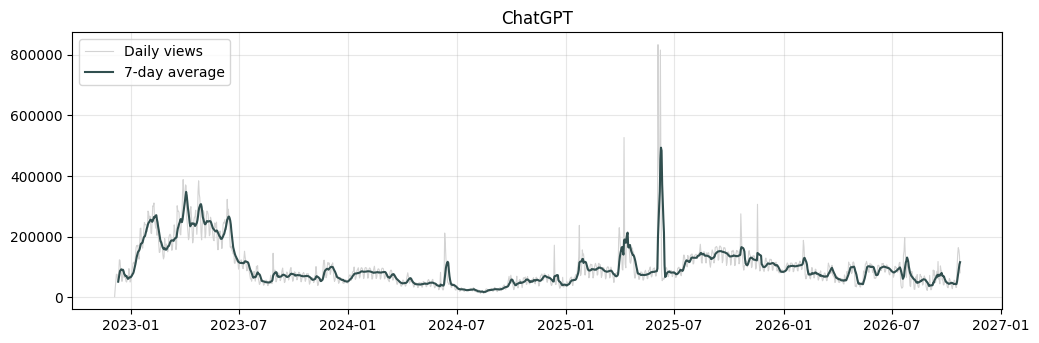

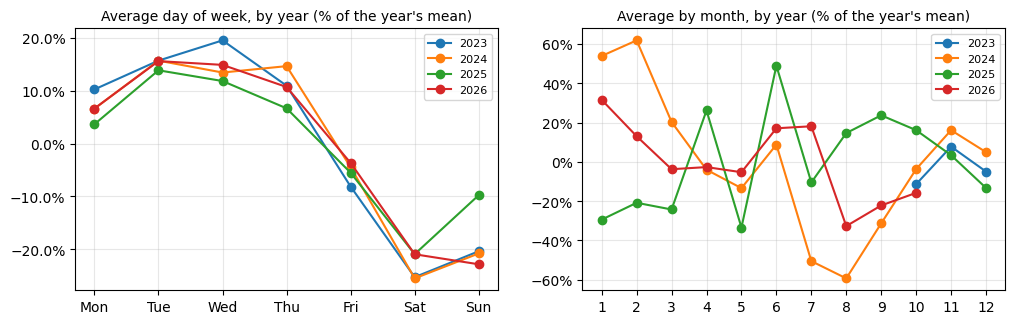

In [3]:
data = pd.read_csv("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/main/lectures/genesis/sdb/data/pageviews.csv", parse_dates=["ds"])
y = data[data["unique_id"] == "ChatGPT"].set_index("ds")["y"].asfreq("D")
print(len(y), y.index.min().date(), y.index.max().date())

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color="lightgray", lw=0.8, label="Daily views")
ax.plot(y.index, y.rolling(7).mean(), color=SLATE, lw=1.5, label="7-day average")
ax.legend(loc="upper left"); ax.set_title('ChatGPT'); plt.show()

recent = y[y.index >= y.index.max() - pd.Timedelta(days=3 * 365)]
rel = recent / recent.groupby(recent.index.year).transform("mean") - 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for year, g in rel.groupby(rel.index.year):
    axes[0].plot(range(7), g.groupby(g.index.dayofweek).mean().reindex(range(7)).values, "o-", label=str(year))
    axes[1].plot(range(1, 13), g.groupby(g.index.month).mean().reindex(range(1, 13)).values, "o-", label=str(year))
axes[0].set_xticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); axes[0].set_title("Average day of week, by year (% of the year's mean)", fontsize=10)
axes[1].set_xticks(range(1, 13)); axes[1].set_title("Average by month, by year (% of the year's mean)", fontsize=10)
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(fontsize=8)
plt.show()

**What the charts say**

- **Weekly rhythm:** Tuesday–Wednesday about 15% above a year's average day, Saturday about 20–25%
  below — the same shape every year: the pattern of work and study.
- **Yearly season — but not a stable one:** deep summer dips in 2024 and 2026 (July–August, school and
  university holidays), none in 2025, when a June spike dominated.
- **Level:** waves rather than a trend — a rise through 2025, a slow decline in 2026, and a jump in the
  very last week of the data.

So a good forecaster must reproduce the week, should not lean too hard on a yearly shape that changes,
and must not extrapolate a trend that is not there.

## 2. The backtest

**Six windows of 28 days**, May to October 2026, each forecast only from the days before it — all after
the release of every foundation model used here. Nine forecasters:

| Classical (fitted to this series) | Foundation models (no fitting) |
|---|---|
| Naive · Seasonal naive · ETS · ARIMA · Theta · MSTL (week + year) | Chronos-2 · TimesFM 2.5 · TiRex |

This cell takes a few minutes — ARIMA and the three downloads are the slow parts.

In [4]:
H, WINDOWS, SEASON = 28, 6, 7
CLASSICAL_MODELS = ["Naive", "Seasonal naive", "ETS", "ARIMA", "Theta", "MSTL"]
FOUNDATION = ["Chronos-2", "TimesFM", "TiRex"]
res, timing = backtest(y, H, WINDOWS, SEASON, CLASSICAL_MODELS, FOUNDATION)
NAMES = CLASSICAL_MODELS + FOUNDATION
print("cut-offs:", [f"{c:%Y-%m-%d}" for c in sorted(res["cutoff"].unique())])

cut-offs: ['2026-05-09', '2026-06-06', '2026-07-04', '2026-08-01', '2026-08-29', '2026-09-26']


## 3. The scoreboard

**MASE** below 1 beats "same day last week" (as it did in the year before the test). **Bias** is the
average over- (+) or under-forecast. **Inside P10–P90** should be close to 80%.

In [5]:
board, scale = score(res, y, SEASON, NAMES, timing)
board.round(3).style.background_gradient(subset=["MASE"], cmap="RdYlGn_r").format(precision=3)

,MASE,"MAPE, %","bias, %",inside P10-P90,seconds
Naive,0.960,37.611,-26.958,1.000,10.092
Seasonal naive,0.881,40.205,5.203,1.000,10.092
ETS,0.781,32.193,-10.648,0.946,10.092
ARIMA,0.758,38.761,13.361,0.976,10.092
Theta,0.694,29.537,-6.613,1.000,10.092
MSTL,1.295,49.961,-21.772,0.863,10.092
Chronos-2,0.742,31.279,-5.275,0.690,3.136
TimesFM,0.766,31.062,-9.463,0.732,2.329
TiRex,0.662,29.795,2.436,0.768,3.301


**What the table says**

- **The best model on this series is not the best on average.** Across the lecture's ten products
  Chronos-2 led; here **TiRex and Theta** — a classical method from 2000 — are ahead of it.
- **MSTL** with a yearly season is the worst: four years of history are too few to estimate a yearly
  shape that also changes.
- Look at the last column: the classical intervals are **too wide** (almost every day inside), the
  foundation models' **too narrow** (about 70–77%). Neither is calibrated out of the box.

## 4. Errors by horizon and by window

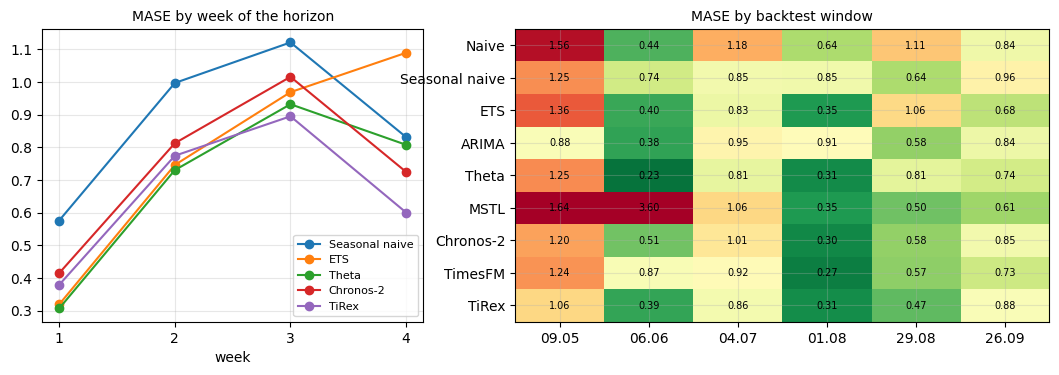

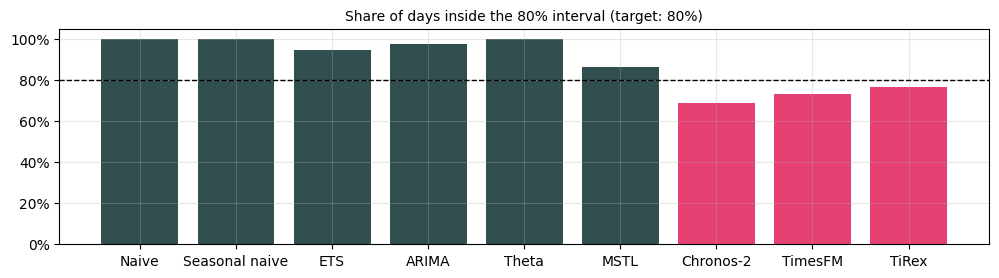

In [6]:
SHOW = ['Seasonal naive', 'ETS', 'Theta', 'Chronos-2', 'TiRex']

by_h = res.groupby((res["h"] - 1) // 7).apply(
    lambda g: pd.Series({m: np.mean(np.abs(g["y"] - g[m])) / scale for m in SHOW}), include_groups=False)
by_w = res.groupby("cutoff").apply(
    lambda g: pd.Series({m: np.mean(np.abs(g["y"] - g[m])) / scale for m in NAMES}), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.4])
for m in SHOW:
    axes[0].plot(by_h.index + 1, by_h[m], "o-", label=m)
axes[0].set_xticks(by_h.index + 1); axes[0].set_xlabel("week"); axes[0].set_title("MASE by week of the horizon", fontsize=10)
axes[0].legend(fontsize=8)
im = axes[1].imshow(by_w.T.values, cmap="RdYlGn_r", vmin=0.2, vmax=1.6, aspect="auto")
axes[1].set_yticks(range(len(NAMES)), NAMES); axes[1].set_xticks(range(len(by_w)), [f"{c:%d.%m}" for c in by_w.index])
for i in range(len(NAMES)):
    for j in range(len(by_w)):
        axes[1].text(j, i, f"{by_w.iloc[j, i]:.2f}", ha="center", va="center", fontsize=7)
axes[1].set_title("MASE by backtest window", fontsize=10)
plt.show()

covered = board["inside P10-P90"].dropna()
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.bar(covered.index, covered.values, color=[PINK if m in FOUNDATION else SLATE for m in covered.index])
ax.axhline(0.8, color="black", lw=1, ls="--")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.set_ylim(0, 1.05)
ax.set_title("Share of days inside the 80% interval (target: 80%)", fontsize=10); plt.show()

- **The first week is the easy one:** its error is about half of the error in weeks 2–4. Re-forecast
  weekly rather than trusting a four-week forecast to the end.
- **Windows differ more than models.** Every model has bad windows (May) and good ones (August). One
  window would have told a different story — which is why there are six.

## 5. A combination, chosen in advance

Week 8 of any forecasting course: an **average** of models is rarely the best and almost never bad. We fix
the pair **before** looking at the scores — one classical model, one foundation model: ETS + Chronos-2.

In [7]:
res["ETS + Chronos-2"] = res[["ETS", "Chronos-2"]].mean(axis=1)
combo_board, _ = score(res, y, SEASON, ["ETS", "Chronos-2", "ETS + Chronos-2"])
combo_board[["MASE", "MAPE, %"]].round(3)

,MASE,"MAPE, %"
ETS,0.781,32.193
Chronos-2,0.742,31.279
ETS + Chronos-2,0.686,28.537


The average beats **both** of its parts. It is not the single best model here — but choosing the single
best by its test score is exactly the mistake a backtest exists to avoid.

## 6. The forecast for the next four weeks

From the full history to 24 October 2026: Chronos-2 with its range, and the ETS + Chronos-2 average.
The series jumped in its last week; both forecasts start high and fall back towards the usual weekly
pattern. Whether the jump lasts is exactly what the width of the range is saying.

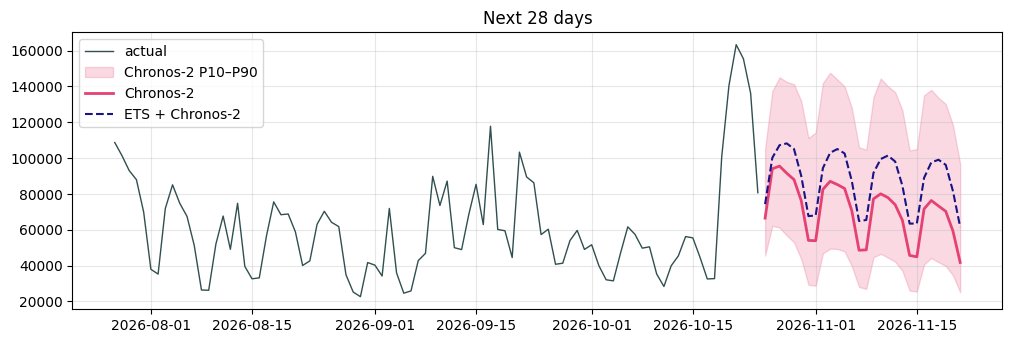

,P10,P50,P90,ETS + Chronos-2
2026-10-25,45582.0,66463.0,105167.0,74281.0
2026-10-26,62170.0,94047.0,137313.0,100160.0
2026-10-27,61233.0,95525.0,145123.0,107202.0
2026-10-28,56765.0,91515.0,142559.0,108205.0
2026-10-29,52986.0,87993.0,141211.0,105076.0
2026-10-30,43615.0,76290.0,131828.0,90061.0
2026-10-31,29257.0,54017.0,111207.0,67589.0
2026-11-01,28743.0,53848.0,114271.0,67974.0
2026-11-02,46873.0,82543.0,141905.0,94409.0
2026-11-03,49421.0,87021.0,147661.0,102949.0


In [8]:
mid, lo, hi = forecast_fm("Chronos-2", y.values, H)
ets = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="D").forecast(
    df=pd.DataFrame({"unique_id": "s", "ds": y.index, "y": y.values}), h=H)["AutoETS"].values
future = pd.date_range(y.index[-1] + pd.Timedelta(days=1), periods=H)
fig, ax = plt.subplots()
ax.plot(y.index[-90:], y.values[-90:], color=SLATE, lw=1, label="actual")
ax.fill_between(future, lo, hi, color=PINK, alpha=0.2, label="Chronos-2 P10–P90")
ax.plot(future, mid, color=PINK, lw=2, label="Chronos-2")
ax.plot(future, (mid + ets) / 2, "--", color=NAVY, lw=1.5, label="ETS + Chronos-2")
ax.legend(loc="upper left"); ax.set_title("Next 28 days"); plt.show()
pd.DataFrame({"P10": lo, "P50": mid, "P90": hi, "ETS + Chronos-2": (mid + ets) / 2}, index=future).round(0).head(14)

## 7. Conclusions

1. **Backtest on your own series.** The model that wins on average (Chronos-2) is mid-table here; a
   2000-era method (Theta) is near the top. No ranking transfers.
2. **The baselines matter.** Six of eight models beat "same day last week" — but not by much, and MSTL
   did not at all.
3. **Plan with the horizon in mind.** Week 1 is roughly twice as accurate as weeks 2–4: refresh the
   forecast every week.
4. **Check the range before using it.** Classical intervals here are too wide, foundation-model
   intervals too narrow. Widen or narrow them by what the backtest shows.
5. **Combine.** A pre-chosen average of a classical and a foundation model beat both — the cheapest
   insurance in forecasting.